## Starting with exploring the data of the Project

In [ ]:
from pathlib import Path
import pandas as pd

RAW_DIR = Path("..") / "data" / "raw"   # the notebook runs from notebooks/, so go up one level

# File sizes in MB, to confirm everything is there
for f in sorted(RAW_DIR.glob("*.csv")):
    print(f"{f.name:28s} {f.stat().st_size / 1e6:8.1f} MB")

building_metadata.csv             0.0 MB
sample_submission.csv           447.6 MB
test.csv                       1462.5 MB
train.csv                       678.6 MB
weather_test.csv                 14.8 MB
weather_train.csv                 7.5 MB


In [ ]:
# Building metadata
meta = pd.read_csv(RAW_DIR / "building_metadata.csv")

print(meta.shape)
meta.head()

(1449, 6)


,site_id,building_id,primary_use,square_feet,year_built,floor_count
0,0,0,Education,7432,2008.0,NaN
1,0,1,Education,2720,2004.0,NaN
2,0,2,Education,5376,1991.0,NaN
3,0,3,Education,23685,2002.0,NaN
4,0,4,Education,116607,1975.0,NaN


In [3]:
# Building Weather
weather = pd.read_csv(RAW_DIR / "weather_train.csv", parse_dates=["timestamp"])

print(weather.shape)
weather.head()

(139773, 9)


,site_id,timestamp,air_temperature,cloud_coverage,dew_temperature,precip_depth_1_hr,sea_level_pressure,wind_direction,wind_speed
0,0,2016-01-01 00:00:00,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
1,0,2016-01-01 01:00:00,24.4,NaN,21.1,-1.0,1020.2,70.0,1.5
2,0,2016-01-01 02:00:00,22.8,2.0,21.1,0.0,1020.2,0.0,0.0
3,0,2016-01-01 03:00:00,21.1,2.0,20.6,0.0,1020.1,0.0,0.0
4,0,2016-01-01 04:00:00,20.0,2.0,20.0,-1.0,1020.0,250.0,2.6


In [4]:
# Find type for each column, non-null count
meta.info(memory_usage="deep")
print()
weather.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   site_id      1449 non-null   int64  
 1   building_id  1449 non-null   int64  
 2   primary_use  1449 non-null   str    
 3   square_feet  1449 non-null   int64  
 4   year_built   675 non-null    float64
 5   floor_count  355 non-null    float64
dtypes: float64(2), int64(3), str(1)
memory usage: 144.2 KB

<class 'pandas.DataFrame'>
RangeIndex: 139773 entries, 0 to 139772
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   site_id             139773 non-null  int64         
 1   timestamp           139773 non-null  datetime64[us]
 2   air_temperature     139718 non-null  float64       
 3   cloud_coverage      70600 non-null   float64       
 4   dew_temperature     139660 non-null  float64       
 5   preci

In [ ]:
print("Metadata, % missing:")
print((meta.isna().mean() * 100).round(1))
print("\nWeather, % missing:")
print((weather.isna().mean() * 100).round(1))

Metadata, % missing:
site_id         0.0
building_id     0.0
primary_use     0.0
square_feet     0.0
year_built     53.4
floor_count    75.5
dtype: float64

Weather, % missing:
site_id                0.0
timestamp              0.0
air_temperature        0.0
cloud_coverage        49.5
dew_temperature        0.1
precip_depth_1_hr     36.0
sea_level_pressure     7.6
wind_direction         4.5
wind_speed             0.2
dtype: float64


### Understanfing Meta and Weather

- `Meta: ` 1,449 buildings, 6 columns
    1. site_id, building_id, primary_use, square_feet : No null values
    2. year_built : 774 values missing out of 1449 (53%)
    3. floor_count : 1094 values missing out of 1449 (75%)

- `Weather: `  139,773 rows, 9 columns
    1. site_id, timestamp : No null values
    2. air_tempreture : 55 missing values (0.04%)
    3. cloud_coverage : 69,173 missing values (49.5%)
    4. dew_temperature : 113 missing values (0.1%)
    5. precip_depth_1_hr : 50,289 missing values (36.0%)
    6. sea_level_pressure :	10,618 missing values (7.6%)
    7. wind_direction : 6,268 missing values (4.5%)
    8. wind_speed : 304 missing values 	(0.2%)

In [ ]:
# Check for duplicates

print("Duplicate metadata rows:", meta.duplicated().sum())
print("building_id unique:", meta["building_id"].is_unique)
print("Duplicate (site_id, timestamp) in weather:",
      weather.duplicated(subset=["site_id", "timestamp"]).sum())

Duplicate metadata rows: 0
building_id unique: True
Duplicate (site_id, timestamp) in weather: 0


In [ ]:
# Check Meta (Number of sites, Buildings per site, Primary use for the building)
print("Number of sites:", meta["site_id"].nunique())    
print("Buildings per site:")
print(meta["site_id"].value_counts().sort_index())
print("Primary use: ", meta["primary_use"].value_counts())

Number of sites: 16
Buildings per site:
site_id
0     105
1      51
2     135
3     274
4      91
5      89
6      44
7      15
8      70
9     124
10     30
11      5
12     36
13    154
14    102
15    124
Name: count, dtype: int64
Primary use:  primary_use
Education                        549
Office                           279
Entertainment/public assembly    184
Public services                  156
Lodging/residential              147
Other                             25
Healthcare                        23
Parking                           22
Warehouse/storage                 13
Manufacturing/industrial          12
Retail                            11
Services                          10
Technology/science                 6
Food sales and service             5
Utility                            4
Religious worship                  3
Name: count, dtype: int64


In [17]:
meta[["square_feet", "year_built", "floor_count"]].describe().round(1)

,square_feet,year_built,floor_count
count,1449.0,675.0,355.0
mean,92111.8,1968.0,3.7
std,110770.0,31.1,3.3
min,283.0,1900.0,1.0
25%,23012.0,1949.0,1.0
50%,57673.0,1970.0,3.0
75%,115676.0,1995.0,5.0
max,875000.0,2017.0,26.0


In [ ]:
# Print the earliest and latest weather timestamp across all sites
print("Weather from", weather["timestamp"].min(), "to", weather["timestamp"].max())

# Build every hour between the first and last timestamp, then count them
expected_hours = len(pd.date_range(weather["timestamp"].min(),   # start: earliest timestamp
                                   weather["timestamp"].max(),   # end: latest timestamp
                                   freq="h"))                    # one step per hour
print("Expected hourly rows per site:", expected_hours)          # a complete site should have this many rows

# One summary row per site
per_site = weather.groupby("site_id").agg(   # split the table into one group per site
    rows=("timestamp", "size"),              # number of rows in that site
    first=("timestamp", "min"),              # that site's earliest timestamp
    last=("timestamp", "max"),               # that site's latest timestamp
)                                            # result: a table indexed by site_id

# Share of the expected hours that each site actually has, in %
per_site["pct_present"] = (per_site["rows"] / expected_hours * 100).round(1)  # e.g. 8784/8784 -> 100.0

# Sort so rows are in time order within each site (diff compares each row to the one above)
weather = weather.sort_values(["site_id", "timestamp"])

# Time since the previous row of the SAME site (first row of each site gives NaT)
gap = weather.groupby("site_id")["timestamp"].diff()

# Biggest gap per site; 1 hour means no missing hours
per_site["max_gap"] = gap.groupby(weather["site_id"]).max()  # group the gaps by site, keep the largest

# Show the summary table (the last line of a cell is displayed automatically)
per_site

Weather from 2016-01-01 00:00:00 to 2016-12-31 23:00:00
Expected hourly rows per site: 8784


,rows,first,last,pct_present,max_gap
site_id,,,,,
0,8784,2016-01-01 00:00:00,2016-12-31 23:00:00,100.0,0 days 01:00:00
1,8763,2016-01-01 00:00:00,2016-12-31 23:00:00,99.8,0 days 06:00:00
2,8783,2016-01-01 00:00:00,2016-12-31 23:00:00,100.0,0 days 02:00:00
3,8780,2016-01-01 00:00:00,2016-12-31 23:00:00,100.0,0 days 02:00:00
4,8783,2016-01-01 01:00:00,2016-12-31 23:00:00,100.0,0 days 01:00:00
5,8755,2016-01-01 01:00:00,2016-12-31 23:00:00,99.7,0 days 09:00:00
6,8782,2016-01-01 01:00:00,2016-12-31 23:00:00,100.0,0 days 02:00:00
7,8614,2016-01-01 00:00:00,2016-12-31 23:00:00,98.1,1 days 16:00:00
8,8784,2016-01-01 00:00:00,2016-12-31 23:00:00,100.0,0 days 01:00:00


In [27]:
# Check train
peek = pd.read_csv(RAW_DIR / "train.csv", nrows=5000)  

print(peek.dtypes)                                     
print()
print(peek.describe())                                  
peek.head()                                             

building_id        int64
meter              int64
timestamp            str
meter_reading    float64
dtype: object

       building_id       meter  meter_reading
count  5000.000000  5000.00000   5.000000e+03
mean    760.867200     0.65700   1.699505e+03
std     446.662264     0.94442   6.488458e+04
min       0.000000     0.00000   0.000000e+00
25%     273.000000     0.00000   3.186550e+00
50%     852.500000     0.00000   3.669000e+01
75%    1169.000000     1.00000   1.519400e+02
max    1448.000000     3.00000   3.241630e+06


,building_id,meter,timestamp,meter_reading
0,0,0,2016-01-01 00:00:00,0.0
1,1,0,2016-01-01 00:00:00,0.0
2,2,0,2016-01-01 00:00:00,0.0
3,3,0,2016-01-01 00:00:00,0.0
4,4,0,2016-01-01 00:00:00,0.0


In [48]:
# Change datatypes for the columns to more compact types to save memory
train_dtypes = {
    "building_id": "int16",    
    "meter": "int8",          
    "meter_reading": "float32" 
}

# Load the full file, with new types
train = pd.read_csv(
    RAW_DIR / "train.csv",     
    dtype=train_dtypes,       
    parse_dates=["timestamp"], 
)

print(train.shape)                                                    
print(f"Memory: {train.memory_usage(deep=True).sum() / 1e6:.0f} MB")  
train.info()                                                           

(20216100, 4)
Memory: 303 MB
<class 'pandas.DataFrame'>
RangeIndex: 20216100 entries, 0 to 20216099
Data columns (total 4 columns):
 #   Column         Dtype         
---  ------         -----         
 0   building_id    int16         
 1   meter          int8          
 2   timestamp      datetime64[us]
 3   meter_reading  float32       
dtypes: datetime64[us](1), float32(1), int16(1), int8(1)
memory usage: 289.2 MB


In [49]:
# Check Missing values, Duplicates and Time range
print("Missing values per column:")
print(train.isna().sum())                                    

# Check duplicate rows that have the same variables in the columns (building_id, meter, timestamp)
dups = train.duplicated(subset=["building_id", "meter", "timestamp"]).sum()  
print("\nDuplicate (building, meter, timestamp) rows:", dups)

# Check the timerange and how many buildings the train file has
print("\nTime range:", train["timestamp"].min(), "to", train["timestamp"].max())  
print("Distinct timestamps:", train["timestamp"].nunique())  
print("Buildings in train:", train["building_id"].nunique(), "of", len(meta))  


Missing values per column:
building_id      0
meter            0
timestamp        0
meter_reading    0
dtype: int64

Duplicate (building, meter, timestamp) rows: 0

Time range: 2016-01-01 00:00:00 to 2016-12-31 23:00:00
Distinct timestamps: 8784
Buildings in train: 1449 of 1449


In [50]:
# Meter Codes : 
# 0 = Electricity
# 1 = Chilled Water
# 2 = Steam
# 3 = Hot Water

meter_summary = train.groupby("meter").agg(            
    rows=("meter_reading", "size"),                     
    buildings=("building_id", "nunique"),                
    median_reading=("meter_reading", "median"),          
    pct_zero=("meter_reading", lambda s: (s == 0).mean() * 100),  
)
meter_summary["pct_of_buildings"] = (meter_summary["buildings"] / len(meta) * 100).round(1)  
meter_summary.round(2)

,rows,buildings,median_reading,pct_zero,pct_of_buildings
meter,,,,,
0,12060910,1413,62.830002,4.40,97.5
1,4182440,498,120.489998,15.70,34.4
2,2708713,324,257.809998,12.81,22.4
3,1264037,145,39.619999,26.93,10.0


In [54]:
electricity = train[train["meter"]==0].drop(columns="meter")

electricity = electricity.merge(meta[["building_id", "site_id"]],
                                on="building_id",
                                how="left")

#del train

print(electricity.shape)
print("Rows without no side id : ", electricity["site_id"].isna().sum())
electricity.head()

(12060910, 4)
Rows without no side id :  0


,building_id,timestamp,meter_reading,site_id
0,0,2016-01-01,0.0,0
1,1,2016-01-01,0.0,0
2,2,2016-01-01,0.0,0
3,3,2016-01-01,0.0,0
4,4,2016-01-01,0.0,0


In [ ]:
# Sumary of electricity meter reading

r = electricity["meter_reading"]

print(r.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).round(1))

print("Zeros: ", (r==0).sum(), "| %:", round((r==0).mean() * 100, 2))
print("Negative results: ", (r < 0).sum(), "| %:", round((r<0).mean() * 100, 2))

print("Top 10 buildings consuming electricity are :")
print(electricity.groupby("building_id")["meter_reading"].max().sort_values(ascending=False).head(10).round(0))


count    12060910.0
mean          170.8
std           380.8
min             0.0
1%              0.0
25%            19.5
50%            62.8
75%           170.1
99%          1629.6
99.9%        4988.0
max         79769.0
Name: meter_reading, dtype: float64
Zeros:  530169 | %: 4.4
Negative results:  0 | %: 0.0
Top 10 buildings consuming electricity are :
building_id
993     79769.0
1168    44336.0
954     41552.0
904     30268.0
799     17502.0
927     12571.0
881     11624.0
955     11019.0
921     10725.0
983     10295.0
Name: meter_reading, dtype: float32


### Analyzing key findings

- The `mean` (170.8) is 2.7x the `median` (62.8). The distribution is strongly right-skewed: a small share of very large readings pulls the mean up.

- The `max` (79,769) is 16x the `99.9th percentile` (4,988). About 12,000 readings (0.1%) lie above 4,988, and a few far beyond it. These could be very large buildings or errors, to check per building and site.

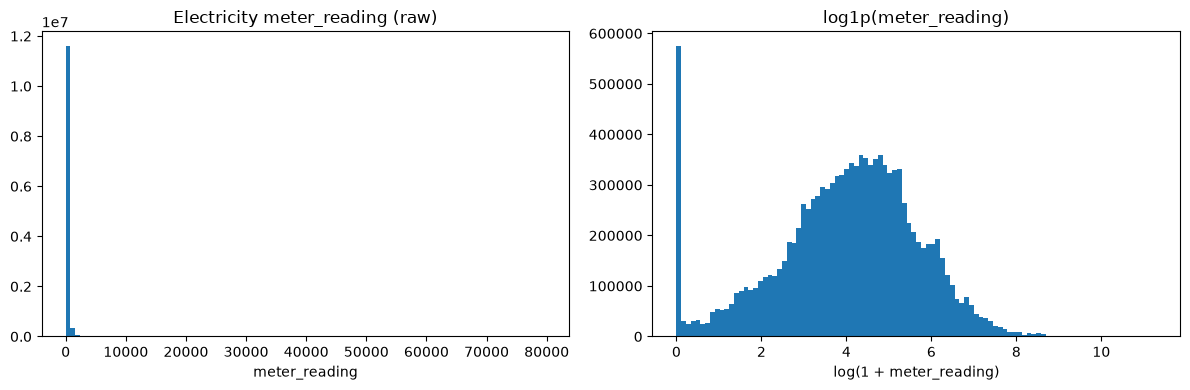

In [74]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))           # two plots side by side

axes[0].hist(r, bins=100)                                  # raw values
axes[0].set_title("Electricity meter_reading (raw)")
axes[0].set_xlabel("meter_reading")

axes[1].hist(np.log1p(r), bins=100)                        # log(1 + x) of the values
axes[1].set_title("log1p(meter_reading)")
axes[1].set_xlabel("log(1 + meter_reading)")

plt.tight_layout()                                         # stop labels from overlapping
plt.show()